<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" alt="VGI" width="280"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Setup and provenance](README.md)

# 01 · Symbol availability and inline expansion are different dimensions

**How much of a frame collection resolves, and how does inline expansion change
its row count?** We will inspect two bundled debug modules, register local symbol
sources, resolve an authored frame column, and preserve every frame when expanding
its inline chain.

Ten synthetic frame records refer to committed Mach-O debug fixtures. No live
process is sampled and no fixture binary is executed. Duplicate addresses represent
separate input frame records; neither these counts nor inline-expanded rows measure
CPU time, crash frequency or the number of incidents.

## Choose symbol availability

`INCLUDE_COMPUTE_SYMBOLS=False` enables only the inline-example debug file. The
experiment changes it to `True`, enabling the second module before any resolution.
Frame addresses stay fixed. **Restart the kernel and run all** after changing it:
worker state and negative-cache entries can survive new connections within one
kernel, so reconnecting alone is not a reliable reset.

In [1]:
INCLUDE_COMPUTE_SYMBOLS = False

In [2]:
import os

os.environ["PLOOMBER_STATS_ENABLED"] = "false"
import haybarn
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from notebook_support import finish, prose, theme

if type(INCLUDE_COMPUTE_SYMBOLS) is not bool:
    raise ValueError("INCLUDE_COMPUTE_SYMBOLS must be True or False.")
summary = expansion = checks = pd.DataFrame()
theme()
con = haybarn.connect()
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.feedback = False
%config SqlMagic.displaycon = False
%sql con
%matplotlib inline

/Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-symbols/notebooks/.venv/lib/python3.14/site-packages/sql/parse.py:339: SyntaxWarning: "\:" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\:"? A raw string is also an option.
  Given a query, replaces all occurrences of ':variable' with '\:variable' and
/Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-symbols/notebooks/.venv/lib/python3.14/site-packages/sql/parse.py:369: SyntaxWarning: "\:" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\:"? A raw string is also an option.
  Given a query, replaces all occurrences of 'example'[x:y] with 'example'[x\:y].


Tip: You may define configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-symbols/notebooks/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-symbols/notebooks/pyproject.toml.

## Attach the release and inspect the debug files

The literal native release needs no local build. `module_info` parses a debug file
without registering it as a resolution source. Both files remain available for this
inspection even when the second source is disabled. Their normalized debug IDs are
different, which is why an address alone cannot identify the right module.

Addresses below are the fixed preferred virtual addresses used by these fixtures'
golden tests. They are not runtime addresses from a loaded process. No ASLR/load-map
conversion is demonstrated. The standalone dSYM files report `image_base=0` here;
that value must not be used to infer a real process's load bias or to rewrite these
known fixture addresses into small offsets.

In [3]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'symbols' (TYPE vgi,LOCATION 'github-auto://Query-farm/vgi-symbols@v0.4.0');
CREATE TABLE modules AS
 SELECT 'inline' AS fixture,* FROM symbols.main.module_info('fixtures/macho_inline.dwarf')
 UNION ALL SELECT 'compute',* FROM symbols.main.module_info('fixtures/macho_compute.dwarf');
CREATE TABLE frames AS SELECT frame_id,build_id,address::UBIGINT AS address
FROM read_json('fixtures/frames.json');
SELECT fixture,format,arch,debug_id,has_line_table,byte_size,image_base FROM modules ORDER BY fixture;

,fixture,format,arch,debug_id,has_line_table,byte_size,image_base
0,compute,MachO,aarch64,4930eb84c7b63ef6a97fbdcdd473f5a30,True,9328,0
1,inline,MachO,aarch64,76ff8518da153e64a8403892fcbf11250,True,9736,0


In [4]:
# Source/cache state belongs to the worker process. Require the promised fresh run
# before adding sources; never clear unrelated state to make this example pass.
assert con.execute("SELECT count(*) FROM symbols.main.sources()").fetchone()[0] == 0, (
    "Restart the kernel: this worker already has configured sources."
)
assert con.execute("SELECT count(*) FROM symbols.main.cache_status()").fetchone()[0] == 0, (
    "Restart the kernel: this worker already has cache state."
)

## Register only the intended local sources

Materialize each source-registration call once. Both sources are local file globs;
the compute source's enabled flag follows the parameter. The source audit exposes
that flag and confirms no remote source is configured. Inspecting a debug file above
does not mean it is enabled for resolution below.

In [5]:
%%sql
CREATE TABLE inline_source AS SELECT * FROM symbols.main.add_source('glob',path=>'fixtures/macho_inline.dwarf');
CREATE TABLE compute_source AS SELECT * FROM symbols.main.add_source('glob',path=>'fixtures/macho_compute.dwarf',enabled=>{{ INCLUDE_COMPUTE_SYMBOLS }});
CREATE TABLE source_audit AS SELECT * FROM symbols.main.sources();
SELECT * FROM source_audit ORDER BY source_id;

,source_id,kind,location,enabled,egress
0,src0,glob,fixtures/macho_inline.dwarf,True,False
1,src1,glob,fixtures/macho_compute.dwarf,False,False


## Resolve each input frame once and retain its original arguments

The scalar accepts build-ID and address columns. Materialize its STRUCT result, then
read the fields locally; displaying each field through a fresh worker call would
repeat resolution and obscure cache counters.

`ok` supplies file/line evidence; `no_line` means a module was found without line
information for the address. In this fixture the far-out address receives a fallback
symbol name with `no_line`, so a non-null name alone does not establish exact address
coverage. `not_found` also covers missing arguments in this release. We preserve
those inputs as separate audit states instead of treating them as an unknown module.

In [6]:
%%sql
CREATE TABLE resolved AS SELECT *,symbols.main.symbolicate(build_id,address) AS result FROM frames;
CREATE TABLE frame_audit AS SELECT frame_id,build_id,address,result.status AS worker_status,
 result.function AS physical_function,regexp_extract(result.file,'([^/]+)$',1) AS source_file,
 result.line AS source_line,result.module AS module_name,result.debug_id AS resolved_debug_id,
 coalesce(len(result.inlined),0) AS inline_levels,
 CASE WHEN build_id IS NULL THEN 'Missing build ID'
 WHEN address IS NULL THEN 'Missing address'
 WHEN result.status='ok' THEN 'File/line resolved'
 WHEN result.status='no_line' THEN 'Module found, no line'
 WHEN result.status='not_found' THEN 'Module not found'
 ELSE result.status END AS resolution_state
FROM resolved;
SELECT * EXCLUDE(build_id,resolved_debug_id) FROM frame_audit ORDER BY frame_id;

,frame_id,address,worker_status,physical_function,source_file,source_line,module_name,inline_levels,resolution_state
0,1,4294968116,ok,apply,prog.c,17,macho_inline.dwarf,2,File/line resolved
1,2,4294968116,ok,apply,prog.c,17,macho_inline.dwarf,2,File/line resolved
2,3,4294968120,ok,apply,prog.c,17,macho_inline.dwarf,2,File/line resolved
3,4,4294968104,ok,apply,prog.c,16,macho_inline.dwarf,0,File/line resolved
4,5,18446744073709486080,no_line,_main,None,<NA>,macho_inline.dwarf,0,"Module found, no line"
5,6,4294968104,not_found,None,None,<NA>,None,0,Module not found
6,7,4294968112,not_found,None,None,<NA>,None,0,Module not found
7,8,4294968116,not_found,None,None,<NA>,None,0,Module not found
8,9,4294968116,not_found,None,None,<NA>,None,0,Missing build ID
9,10,<NA>,not_found,None,None,<NA>,None,0,Missing address


In [7]:
%%sql summary <<
SELECT s.resolution_state,count(a.frame_id) AS frames FROM (VALUES
 (1,'File/line resolved'),(2,'Module found, no line'),(3,'Module not found'),
 (4,'Missing build ID'),(5,'Missing address')
) AS s(sort_order,resolution_state)
LEFT JOIN frame_audit a USING(resolution_state)
GROUP BY s.sort_order,s.resolution_state ORDER BY s.sort_order;

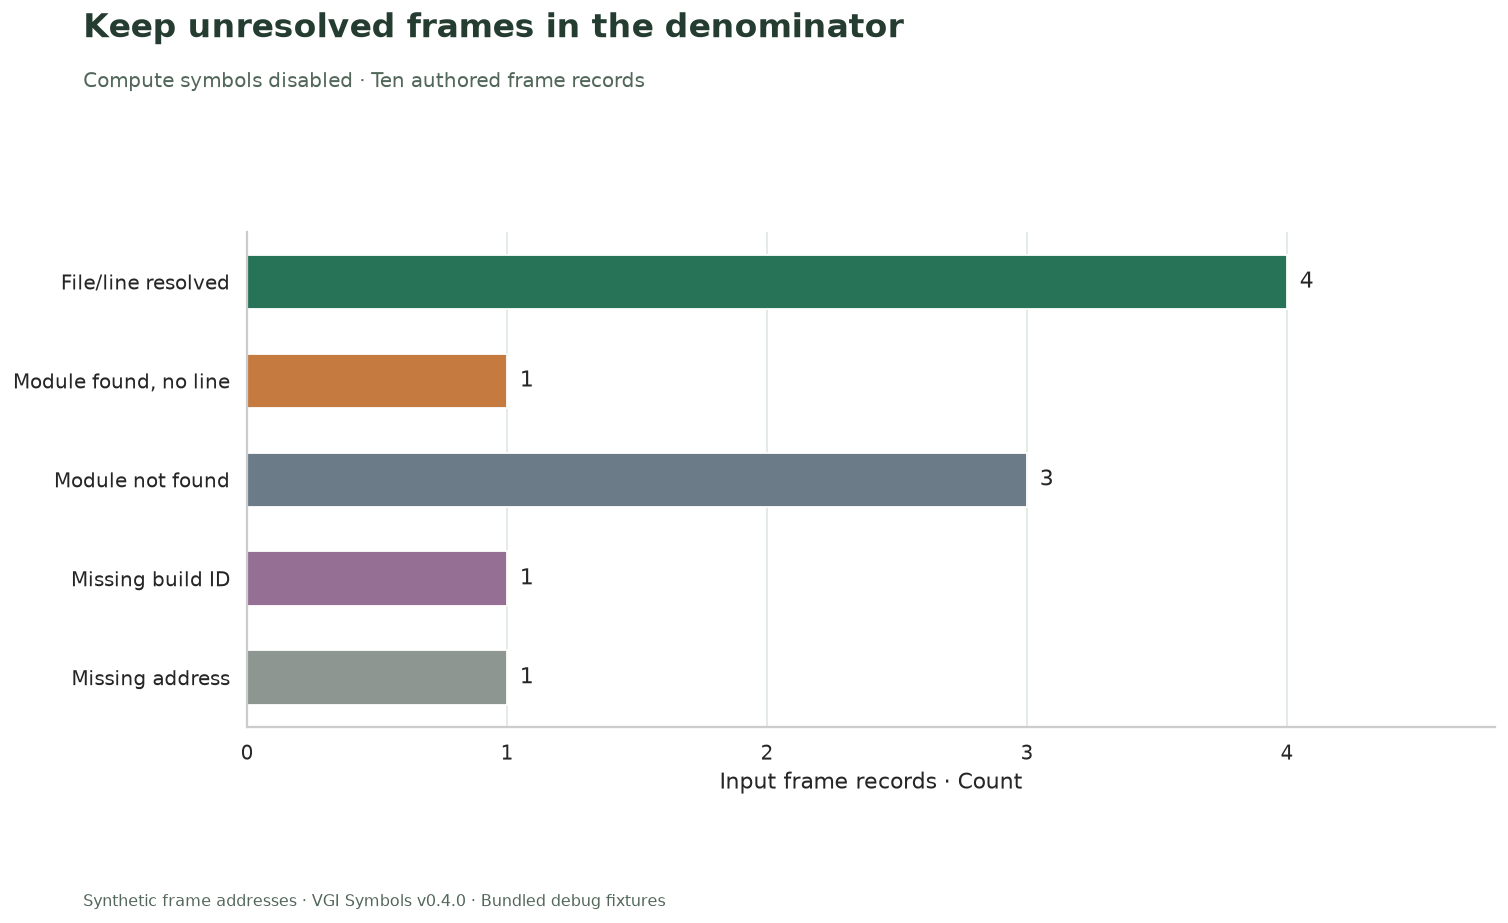

**4 of 10 input frame records have file/line resolution.** The no-line case, unavailable module and missing arguments remain distinct. A symbol-like fallback name must not be counted as file/line coverage.

In [8]:
fig, ax = plt.subplots(figsize=(12, 7.2))
bars = ax.barh(
    summary.resolution_state,
    summary.frames,
    color=["#267358", "#c57b40", "#6b7b88", "#956f94", "#8d9690"],
    height=0.55,
)
ax.bar_label(bars, padding=7, fontsize=12)
ax.invert_yaxis()
ax.set_xlim(0, max(1, summary.frames.max()) * 1.2)
ax.set_xlabel("Input frame records · Count")
ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
ax.grid(axis="y", visible=False)
finish(
    fig,
    "Keep unresolved frames in the denominator",
    f"Compute symbols {'enabled' if INCLUDE_COMPUTE_SYMBOLS else 'disabled'} · Ten authored frame records",
    "01_resolution_coverage.png",
    bottom=0.12,
)
ok = int(summary.loc[summary.resolution_state == "File/line resolved", "frames"].iloc[0])
prose(
    f"**{ok} of {int(summary.frames.sum())} input frame records have file/line resolution.** "
    "The no-line case, unavailable module and missing arguments remain distinct. A symbol-like fallback name must not be counted as file/line coverage."
)

## Expand inline chains without losing physical-frame records

The scalar's `function` is the physical function, while its `inlined` list contains
only inline callees, innermost first. The `function_name` fast path instead returns
the innermost name when one exists. Choose the meaning needed for your grouping.

A bare `UNNEST` would drop frames with empty inline lists. We explicitly add one
physical-record row for every input, then union its inline rows. `depth=0` starts
at the innermost inline callee; the physical record comes last. Unknown-module and missing-argument records remain present with NULL names;
the no-line fallback retains its name and original status.

In [9]:
%%sql
CREATE TABLE expanded AS
 SELECT frame_id,coalesce(len(result.inlined),0)::BIGINT AS depth,false AS is_inline,
 result.function AS function_name,regexp_extract(result.file,'([^/]+)$',1) AS source_file,
 result.line AS source_line,result.status AS worker_status FROM resolved
 UNION ALL
 SELECT r.frame_id,u.depth,true,u.frame.function,regexp_extract(u.frame.file,'([^/]+)$',1),
 u.frame.line,r.result.status
 FROM resolved r,UNNEST(list_transform(r.result.inlined,lambda x,i: struct_pack(depth:=i-1,frame:=x))) AS t(u);
SELECT * FROM expanded ORDER BY frame_id,depth;

,frame_id,depth,is_inline,function_name,source_file,source_line,worker_status
0,1,0,True,inner_lo,prog.c,9,ok
1,1,1,True,inner_hi,prog.c,13,ok
2,1,2,False,apply,prog.c,17,ok
3,2,0,True,inner_lo,prog.c,9,ok
4,2,1,True,inner_hi,prog.c,13,ok
5,2,2,False,apply,prog.c,17,ok
6,3,0,True,inner_lo,prog.c,9,ok
7,3,1,True,inner_hi,prog.c,13,ok
8,3,2,False,apply,prog.c,17,ok
9,4,0,False,apply,prog.c,16,ok


In [10]:
%%sql expansion <<
SELECT frame_id,count(*) FILTER(WHERE NOT is_inline) AS physical_records,
 count(*) FILTER(WHERE is_inline) AS inline_rows,count(*) AS expanded_rows
FROM expanded GROUP BY frame_id ORDER BY frame_id;

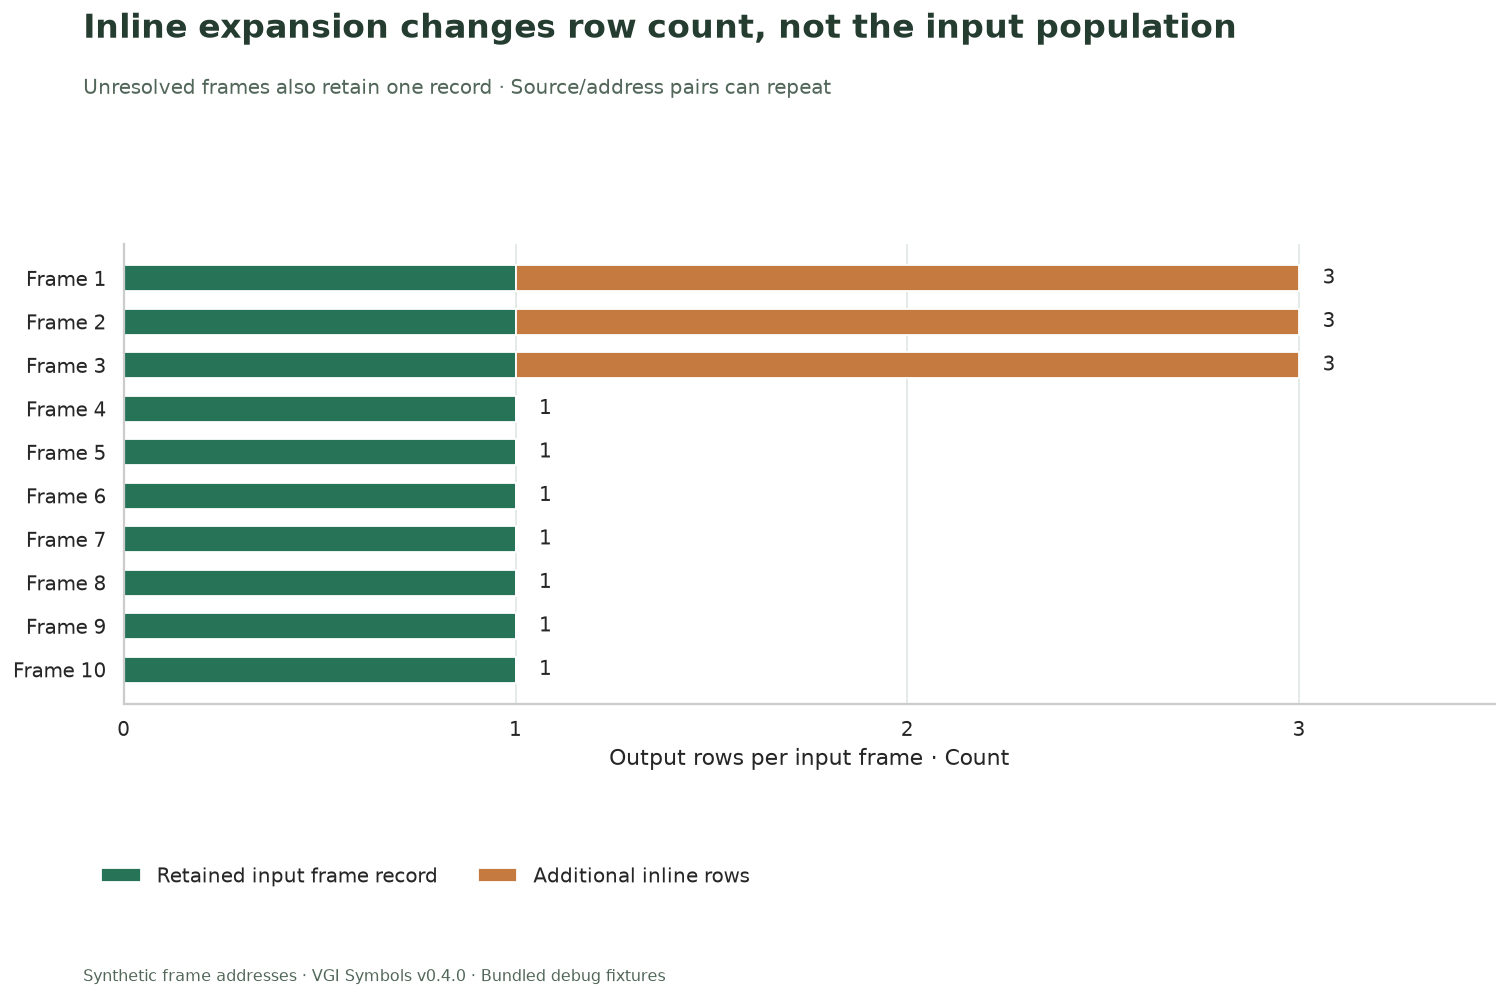

**10 input frames become 16 output rows**, including **6 inline rows**. Counting those expanded rows as physical frames would inflate the denominator. Repeated addresses keep distinct frame IDs and must not be silently deduplicated.

In [11]:
fig, ax = plt.subplots(figsize=(12, 7.8))
labels = [f"Frame {i}" for i in expansion.frame_id]
ax.barh(
    labels,
    expansion.physical_records,
    color="#267358",
    label="Retained input frame record",
    height=0.6,
)
ax.barh(
    labels,
    expansion.inline_rows,
    left=expansion.physical_records,
    color="#c57b40",
    label="Additional inline rows",
    height=0.6,
)
for i, total in enumerate(expansion.expanded_rows):
    ax.text(total + 0.06, i, str(int(total)), va="center", fontsize=11)
ax.invert_yaxis()
ax.set_xlim(0, max(1, expansion.expanded_rows.max()) + 0.5)
ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
ax.set_xlabel("Output rows per input frame · Count")
ax.grid(axis="y", visible=False)
fig.legend(
    *ax.get_legend_handles_labels(),
    loc="lower left",
    bbox_to_anchor=(0.08, 0.10),
    ncol=2,
    frameon=False,
)
finish(
    fig,
    "Inline expansion changes row count, not the input population",
    "Unresolved frames also retain one record · Source/address pairs can repeat",
    "02_inline_expansion.png",
    bottom=0.21,
)
prose(
    f"**{len(expansion)} input frames become {int(expansion.expanded_rows.sum())} output rows**, "
    f"including **{int(expansion.inline_rows.sum())} inline rows**. "
    "Counting those expanded rows as physical frames would inflate the denominator. Repeated addresses keep distinct frame IDs and must not be silently deduplicated."
)

## Inspect the cache without making a timing claim

`cache_status` distinguishes resident parsed modules from remembered misses. Its
counters describe worker activity, not the number of input records or a timing
benchmark. We materialized one frame scan, but do not infer a parse count from the
resident count; the source test suite verifies the parse-once invariant separately.
A fresh kernel is the reset boundary for this notebook's experiment.

In [12]:
%%sql
CREATE TABLE cache_snapshot AS SELECT * FROM symbols.main.cache_status();
SELECT debug_id,name,format,bytes_resident,rows_resolved,resident FROM cache_snapshot ORDER BY debug_id;

,debug_id,name,format,bytes_resident,rows_resolved,resident
0,00000000000000000000000000000000a,,,0,0,False
1,4930eb84c7b63ef6a97fbdcdd473f5a30,,,0,0,False
2,76ff8518da153e64a8403892fcbf11250,macho_inline.dwarf,MachO,9736,4,True


## Verify coverage, source scope and expansion

These assertions check the fixed fixture contract, including the out-of-range
`no_line` result and missing-argument `not_found` behavior. They ensure every input
survives expansion and that a newly available module changes resolution, not the
frame inventory.

In [13]:
%%sql checks <<
SELECT 'All ten frame IDs are retained once before expansion' AS check_name,
 (SELECT count(*)=10 AND count(DISTINCT frame_id)=10 FROM frame_audit) AS passed
UNION ALL SELECT 'Distinct fixtures carry line tables and distinct debug IDs',
 (SELECT count(*)=2 AND count(DISTINCT debug_id)=2 AND bool_and(has_line_table) FROM modules)
UNION ALL SELECT 'Only local sources are configured',
 (SELECT count(*)=2 AND bool_and(kind='glob' AND NOT egress) FROM source_audit)
UNION ALL SELECT 'Compute source follows its enabled parameter',
 (SELECT enabled={{ INCLUDE_COMPUTE_SYMBOLS }} FROM source_audit WHERE location='fixtures/macho_compute.dwarf')
UNION ALL SELECT 'Duplicate address records survive as separate frames',
 (SELECT count(*)=2 AND count(DISTINCT address)=1 AND bool_and(worker_status='ok') FROM frame_audit WHERE frame_id IN (1,2))
UNION ALL SELECT 'The far-out address retains no-line status',
 (SELECT worker_status='no_line' AND source_line IS NULL FROM frame_audit WHERE frame_id=5)
UNION ALL SELECT 'Unknown module remains unresolved',
 (SELECT resolution_state='Module not found' FROM frame_audit WHERE frame_id=8)
UNION ALL SELECT 'Missing argument states are retained despite identical worker status',
 (SELECT count(DISTINCT resolution_state)=2 AND bool_and(worker_status='not_found') FROM frame_audit WHERE frame_id IN (9,10))
UNION ALL SELECT 'Compute frames resolve only with their source enabled',
 (SELECT bool_and((worker_status='ok')={{ INCLUDE_COMPUTE_SYMBOLS }}) FROM frame_audit WHERE frame_id IN (6,7))
UNION ALL SELECT 'Every input has exactly one retained physical record',
 (SELECT count(*)=10 AND count(DISTINCT frame_id)=10 FROM expanded WHERE NOT is_inline)
UNION ALL SELECT 'Expanded rows reconcile to input plus inline-list lengths',
 (SELECT count(*) FROM expanded)=(SELECT count(*)+sum(inline_levels) FROM frame_audit)
UNION ALL SELECT 'Inline order is innermost first before the physical function',
 (SELECT list(function_name ORDER BY depth)=['inner_lo','inner_hi','apply'] FROM expanded WHERE frame_id=1);

In [14]:
display(checks)
assert checks.passed.fillna(False).all(), checks.loc[~checks.passed.fillna(False)]
assert int(summary.frames.sum()) == len(expansion)
assert (
    int(expansion.physical_records.sum())
    == con.execute("SELECT count(*) FROM frames").fetchone()[0]
)
prose(
    f"**{len(checks)} SQL checks and two chart reconciliations passed.** Resolution coverage and inline-expanded row counts answer different questions."
)

,check_name,passed
0,All ten frame IDs are retained once before exp...,True
1,Distinct fixtures carry line tables and distin...,True
2,Only local sources are configured,True
3,Compute source follows its enabled parameter,True
4,Duplicate address records survive as separate ...,True
5,The far-out address retains no-line status,True
6,Unknown module remains unresolved,True
7,Missing argument states are retained despite i...,True
8,Compute frames resolve only with their source ...,True
9,Every input has exactly one retained physical ...,True


**12 SQL checks and two chart reconciliations passed.** Resolution coverage and inline-expanded row counts answer different questions.

## Experiment: make the second module's symbols available

Change **`INCLUDE_COMPUTE_SYMBOLS=False` to `True`**, restart the kernel and run all.
Predict that frames 6 and 7 change from `not_found` to file/line resolution while
input IDs, the no-line case and the unknown-module case stay fixed. The second
module has no inline chain at these addresses, so the inline-expansion chart should
remain unchanged.

This is a source-availability experiment, not a change to captured frames or evidence
of runtime performance. A fresh kernel avoids stale negative-cache results from an
earlier source configuration. Reset to **`False`** to restore the saved example.

In [15]:
con.close()

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Notebook setup and provenance](README.md)